In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path


print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

OpenCV: 5.0.0
NumPy: 2.5.4


In [2]:
# Directorio del proyecto (ejecutar el notebook desde esta carpeta)
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "datasets"
WHITE_PATCH_DIR = DATA_DIR / "white_patch"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_WP_DIR = OUTPUT_DIR / "white_patch"
OUTPUT_HIST_DIR = OUTPUT_DIR / "histogramas"

for directory in [OUTPUT_WP_DIR, OUTPUT_HIST_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Directorio del proyecto:", PROJECT_DIR)
print("Estructura de directorios creada correctamente.")

Directorio del proyecto: c:\Users\Duvan Orozco\Desktop\DUVAN\UBA\ESPECIALIZACION INTELIGENCIA ARTIFICIAL\3. Tercer Bimestre\Vision por computadora\TP1
Estructura de directorios creada correctamente.


In [3]:
# Archivos correspondientes a White-Patch
white_patch_files = [
    "test_blue.png",
    "test_green.png",
    "test_red.png",
    "wp_blue.jpg",
    "wp_green.png",
    "wp_green2.jpg",
    "wp_red.png",
    "wp_red2.jpg"
]

# Archivos correspondientes a histogramas
histogram_files = [
    "img1_tp.png",
    "img2_tp.png"
]

missing_files = [name for name in white_patch_files if not (WHITE_PATCH_DIR / name).is_file()]
missing_files += [name for name in histogram_files if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError("Faltan imágenes del dataset: " + ", ".join(missing_files))

print(f"Dataset completo: {len(white_patch_files) + len(histogram_files)} imágenes encontradas.")


Dataset completo: 10 imágenes encontradas.


In [4]:
print("IMÁGENES WHITE-PATCH")

for filename in sorted(path.name for path in WHITE_PATCH_DIR.iterdir() if path.is_file()):
    print(filename)

print("\nIMÁGENES PARA HISTOGRAMAS")

for filename in histogram_files:
    path = (DATA_DIR / filename)
    print(filename, "->", path.exists())

IMÁGENES WHITE-PATCH
test_blue.png
test_green.png
test_red.png
wp_blue.jpg
wp_green.png
wp_green2.jpg
wp_red.png
wp_red2.jpg

IMÁGENES PARA HISTOGRAMAS
img1_tp.png -> True
img2_tp.png -> True


##Parte 1 Desarrollo de Algoritmo White Patch

In [5]:
white_patch_images = {}

for filename in white_patch_files:
    path = (WHITE_PATCH_DIR / filename)
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        print(f"No se pudo cargar: {filename}")
        continue
    white_patch_images[filename] = image

image_info = []

for filename, image in white_patch_images.items():
    height, width, channels = image.shape
    image_info.append({
        "Imagen": filename,
        "Alto": height,
        "Ancho": width,
        "Canales": channels,
        "Tipo de dato": str(image.dtype),
        "Tamaño (KB)": round(image.nbytes / 1024, 2)
    })
df_images = pd.DataFrame(image_info)
display(df_images)

,Imagen,Alto,Ancho,Canales,Tipo de dato,Tamaño (KB)
0,test_blue.png,100,278,3,uint8,81.45
1,test_green.png,100,278,3,uint8,81.45
2,test_red.png,99,276,3,uint8,80.05
3,wp_blue.jpg,1600,1200,3,uint8,5625.00
4,wp_green.png,571,363,3,uint8,607.25
5,wp_green2.jpg,1600,1200,3,uint8,5625.00
6,wp_red.png,813,481,3,uint8,1145.66
7,wp_red2.jpg,1600,1200,3,uint8,5625.00


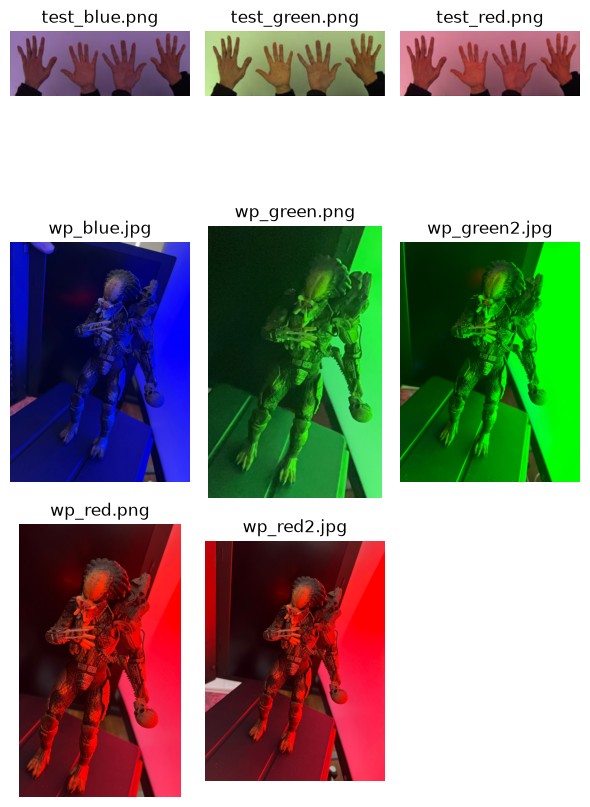

In [6]:
def show_images(images, columns=3):
    filenames = list(images.keys())
    rows = int(np.ceil(len(filenames) / columns))
    plt.figure(figsize=(6, 3 * rows))
    for i, filename in enumerate(filenames):
        image = cv2.cvtColor(
            images[filename],
            cv2.COLOR_BGR2RGB
        )
        plt.subplot(rows, columns, i + 1)
        plt.imshow(image)
        plt.title(filename)
        plt.axis("off")
    plt.tight_layout()
    plt.show()
show_images(white_patch_images)

In [7]:
def white_patch(image):

    image_float = image.astype(np.float32)
    max_values = np.max(image_float, axis=(0, 1))
    scale_factors = np.divide(255.0,max_values,out=np.ones_like(max_values),where=max_values > 0)
    corrected = image_float * scale_factors
    corrected = np.clip(corrected, 0, 255)
    corrected = np.rint(corrected).astype(np.uint8)

    return corrected, max_values, scale_factors

In [8]:
corrected_images = {}

results = []

for filename, image in white_patch_images.items():
    corrected, max_values, scale_factors = white_patch(image)
    corrected_images[filename] = corrected
    results.append({
        "Imagen": filename,
        "Máximo B": max_values[0],
        "Máximo G": max_values[1],
        "Máximo R": max_values[2],
        "Factor B": scale_factors[0],
        "Factor G": scale_factors[1],
        "Factor R": scale_factors[2]
    })

    output_path = (OUTPUT_WP_DIR / filename)
    cv2.imwrite(str(output_path), corrected)

df_white_patch = pd.DataFrame(results)
display(df_white_patch.round(3))

,Imagen,Máximo B,Máximo G,Máximo R,Factor B,Factor G,Factor R
0,test_blue.png,200.0,138.0,165.0,1.275,1.848,1.545
1,test_green.png,171.0,250.0,210.0,1.491,1.020,1.214
2,test_red.png,175.0,157.0,247.0,1.457,1.624,1.032
3,wp_blue.jpg,255.0,255.0,255.0,1.000,1.000,1.000
4,wp_green.png,155.0,252.0,126.0,1.645,1.012,2.024
5,wp_green2.jpg,172.0,255.0,170.0,1.483,1.000,1.500
6,wp_red.png,122.0,134.0,255.0,2.090,1.903,1.000
7,wp_red2.jpg,203.0,201.0,255.0,1.256,1.269,1.000


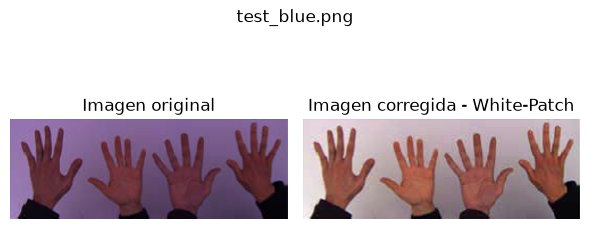

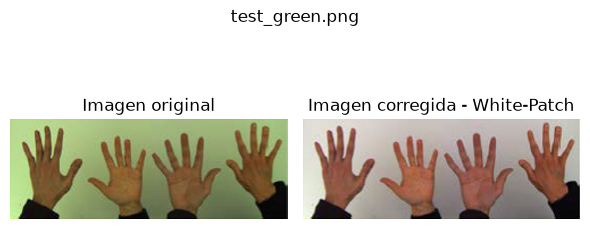

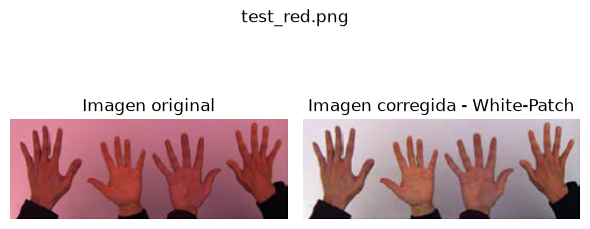

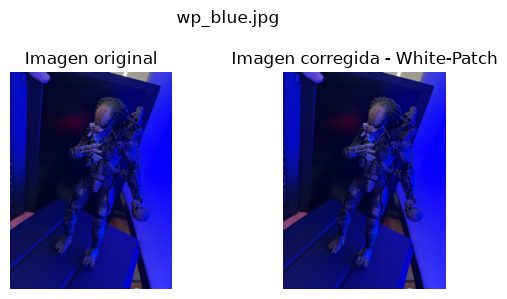

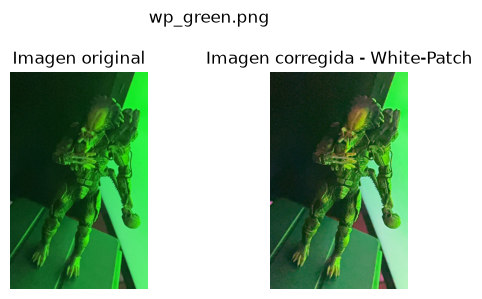

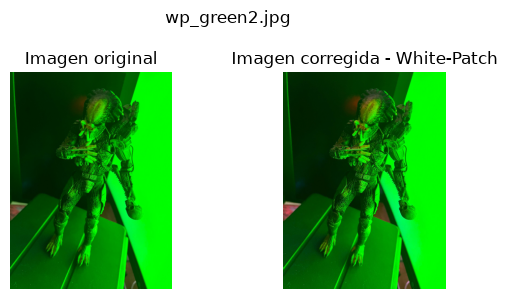

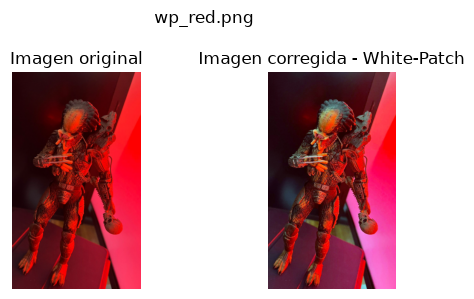

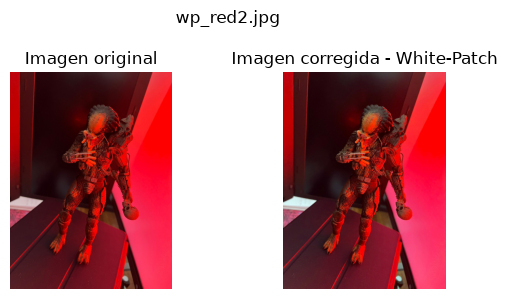

In [9]:
for filename in white_patch_images:

    original = cv2.cvtColor( white_patch_images[filename],  cv2.COLOR_BGR2RGB )
    corrected = cv2.cvtColor( corrected_images[filename], cv2.COLOR_BGR2RGB )
    plt.figure(figsize=(6, 3))

    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.title("Imagen original")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(corrected)
    plt.title("Imagen corregida - White-Patch")
    plt.axis("off")

    plt.suptitle(filename)
    plt.tight_layout()
    plt.show()

In [10]:
verification = []

for filename, image in corrected_images.items():
    max_after = np.max(image.astype(np.float32), axis=(0, 1))

    verification.append({
        "Imagen": filename,
        "Máximo B corregido": max_after[0],
        "Máximo G corregido": max_after[1],
        "Máximo R corregido": max_after[2]
    })

df_verification = pd.DataFrame(verification)
display(df_verification)

,Imagen,Máximo B corregido,Máximo G corregido,Máximo R corregido
0,test_blue.png,255.0,255.0,255.0
1,test_green.png,255.0,255.0,255.0
2,test_red.png,255.0,255.0,255.0
3,wp_blue.jpg,255.0,255.0,255.0
4,wp_green.png,255.0,255.0,255.0
5,wp_green2.jpg,255.0,255.0,255.0
6,wp_red.png,255.0,255.0,255.0
7,wp_red2.jpg,255.0,255.0,255.0


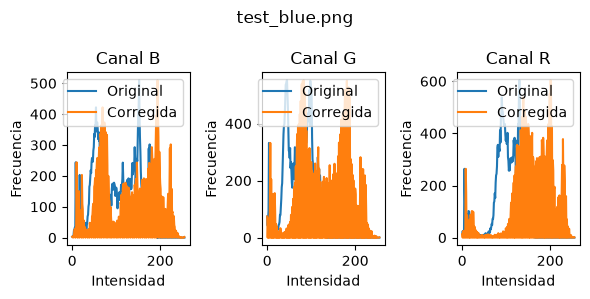

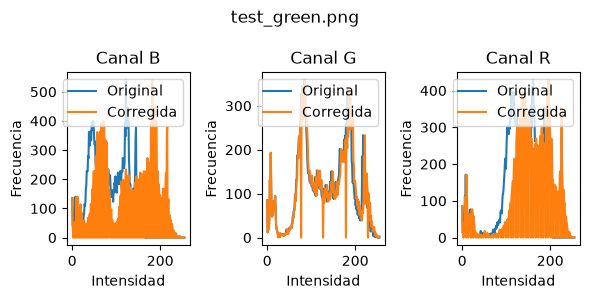

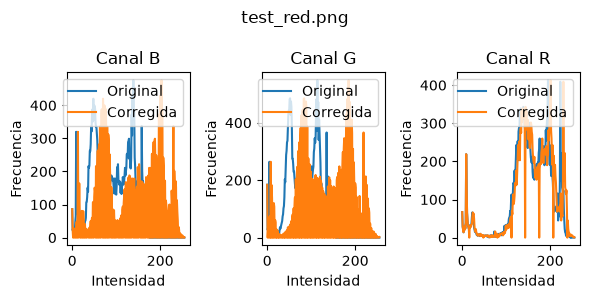

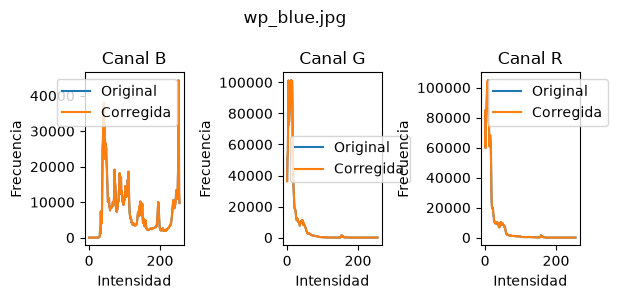

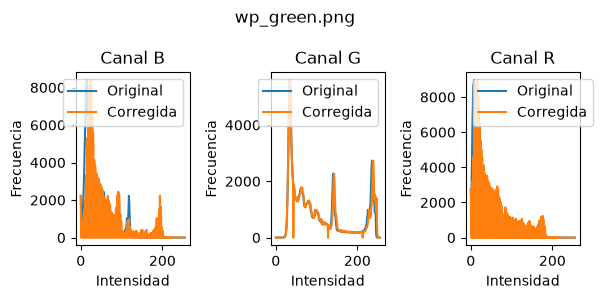

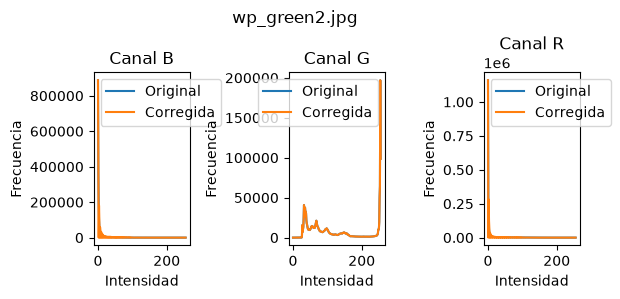

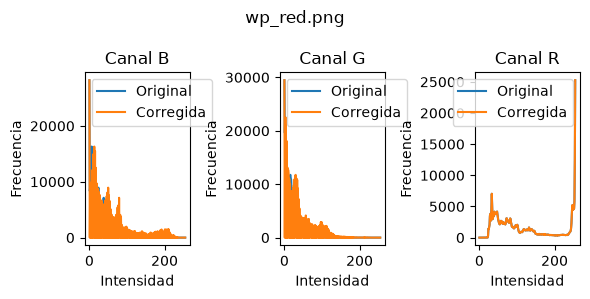

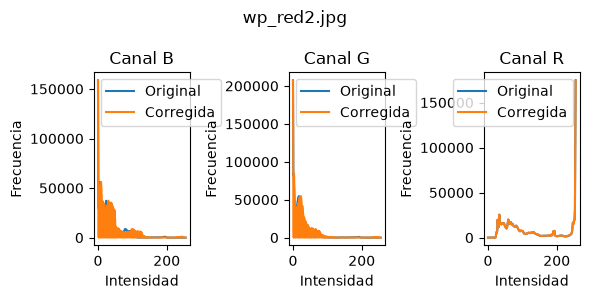

In [11]:
def plot_rgb_histograms(original, corrected, filename):

    colors = ["b", "g", "r"]
    plt.figure(figsize=(6, 3))

    for i, color in enumerate(colors):

        plt.subplot(1, 3, i + 1)
        hist_original = cv2.calcHist(
            [original],
            [i],
            None,
            [256],
            [0, 256]
        )

        hist_corrected = cv2.calcHist(
            [corrected],
            [i],
            None,
            [256],
            [0, 256]
        )

        plt.plot(hist_original, label="Original", linewidth=1.5)
        plt.plot(hist_corrected, label="Corregida", linewidth=1.5)

        plt.title(f"Canal {color.upper()}")
        plt.xlabel("Intensidad")
        plt.ylabel("Frecuencia")
        plt.legend()

    plt.suptitle(filename)
    plt.tight_layout()
    plt.show()


for filename in white_patch_images:

    plot_rgb_histograms(
        white_patch_images[filename],
        corrected_images[filename],
        filename
    )

## Parte 2 Escala de grises y visualizarlas

In [12]:
# Rutas de las imágenes
img1_path = DATA_DIR / "img1_tp.png"
img2_path = DATA_DIR / "img2_tp.png"

# Leer imágenes en escala de grises
img1 = cv2.imread(str(img1_path), cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread(str(img2_path), cv2.IMREAD_GRAYSCALE)

# Validar lectura
if img1 is None or img2 is None:
    raise ValueError("No se pudieron cargar las imágenes.")

print("Imagen 1:", img1.shape)
print("Imagen 2:", img2.shape)

print("Tipo de dato:", img1.dtype, img2.dtype)

Imagen 1: (288, 287)
Imagen 2: (288, 287)
Tipo de dato: uint8 uint8


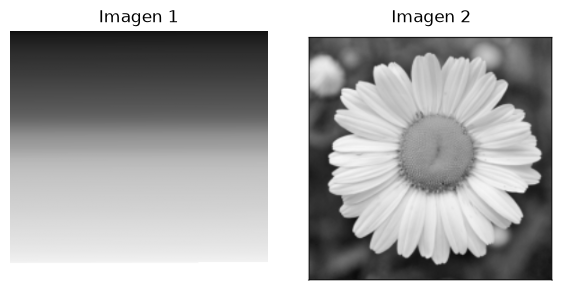

In [13]:
plt.figure(figsize=(6, 3))

plt.subplot(1, 2, 1)
plt.imshow(img1, cmap="gray", vmin=0, vmax=255)
plt.title("Imagen 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img2, cmap="gray", vmin=0, vmax=255)
plt.title("Imagen 2")
plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
# Calcular histograma de la imagen 1
hist1 = cv2.calcHist(
    [img1],
    [0],
    None,
    [256],
    [0, 256]
)

# Calcular histograma de la imagen 2
hist2 = cv2.calcHist(
    [img2],
    [0],
    None,
    [256],
    [0, 256]
)

print("Dimensiones histograma 1:", hist1.shape)
print("Dimensiones histograma 2:", hist2.shape)

Dimensiones histograma 1: (256,)
Dimensiones histograma 2: (256,)


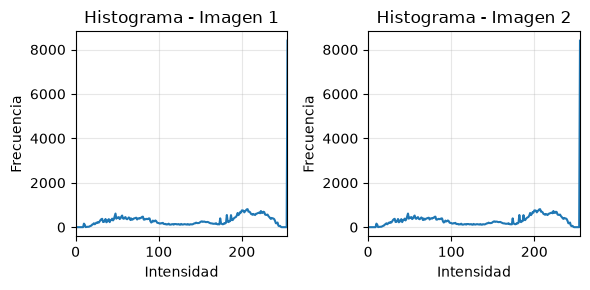

In [15]:
plt.figure(figsize=(6, 3))

plt.subplot(1, 2, 1)

plt.plot(hist1)
plt.title("Histograma - Imagen 1")
plt.xlabel("Intensidad")
plt.ylabel("Frecuencia")
plt.xlim(0, 255)
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)

plt.plot(hist2)
plt.title("Histograma - Imagen 2")
plt.xlabel("Intensidad")
plt.ylabel("Frecuencia")
plt.xlim(0, 255)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
histograms_equal = np.array_equal(hist1, hist2)
histogram_difference = np.abs(hist1 - hist2)
total_difference = np.sum(histogram_difference)
max_difference = np.max(histogram_difference)

print("¿Los histogramas son idénticos?", histograms_equal)
print("Diferencia total:", total_difference)
print("Diferencia máxima entre bins:", max_difference)

¿Los histogramas son idénticos? True
Diferencia total: 0.0
Diferencia máxima entre bins: 0.0


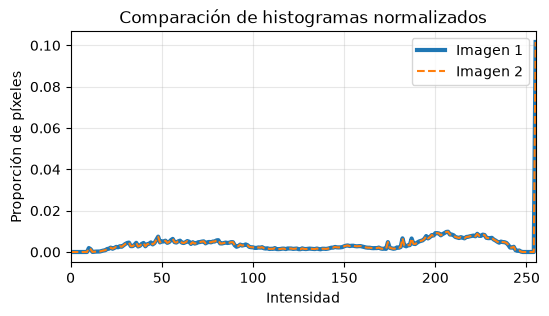

In [17]:
hist1_norm = hist1 / hist1.sum()
hist2_norm = hist2 / hist2.sum()

plt.figure(figsize=(6, 3))

plt.plot(hist1_norm, label="Imagen 1", linewidth=3)
plt.plot(hist2_norm, label="Imagen 2",
         linestyle="--", linewidth=1.5)

plt.title("Comparación de histogramas normalizados")
plt.xlabel("Intensidad")
plt.ylabel("Proporción de píxeles")

plt.xlim(0, 255)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Selección del número de bins
Para este ejercicio elegí 256 bins porque las imágenes están en escala de grises y tienen 256 niveles de intensidad, desde 0 (negro) hasta 255 (blanco). De esta manera, podemos observar la frecuencia de cada nivel sin agruparlos.

### Comparación de los histogramas
Al comparar los histogramas observé que las dos imágenes tienen exactamente la misma distribución de intensidades. Esto lo comprobé mediante código y obtuve una diferencia de cero entre ambos histogramas.
Lo interesante es que las imágenes son visualmente diferentes, pero tienen la misma cantidad de píxeles para cada nivel de intensidad. Esto demuestra que los histogramas muestran cómo se distribuyen los valores de los píxeles, pero no indican dónde están ubicados dentro de la imagen.

### Histogramas como características (features)
Considero que los histogramas sí pueden ser útiles como características para entrenar modelos de Machine Learning, porque permiten representar una imagen mediante valores numéricos que describen la distribución de sus intensidades.
Sin embargo, tienen una limitación: no conservan la ubicación ni la forma de los objetos. Como vimos en este ejercicio, dos imágenes diferentes pueden tener exactamente el mismo histograma.
Por eso, pueden ser útiles para algunos problemas de clasificación, pero no serían suficientes por sí solos para detectar objetos o reconocer formas. Para esos casos sería necesario utilizar otras características o modelos más avanzados, como las redes neuronales convolucionales.

